# Predicting Airline Satisfaction (Kaggle competition)
- This notebook is for training a model to sumbit predictions in the Kaggle competition.
## Data inspection
We have got three files from competition website.
- `train.csv` - the training set, with `satisfaction` as target
- `test.csv` - the test set, used to predict the probability for satisfaction
- `sample_submission.csv` - a sample submission file in the correct format

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [13]:
original_data = pd.read_csv("/content/Datasets/train.csv")

y = original_data["satisfaction"]
X = original_data.drop(["id", "satisfaction"], axis=1)

original_data.head()

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,...,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
1,1,56,651,5,5,5,5,5,4,4,...,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,True
2,2,31,1371,3,4,2,5,3,3,3,...,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
3,3,10,1616,3,5,3,3,3,3,3,...,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,False
4,4,23,481,3,4,3,4,5,3,5,...,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,False


We can now see that data has 699,634 rows and 21 columns, which is quite big.
Let's see what are the features names. We are going to inspect by separating the numerical features and categorical features.

In [14]:
print("Numerical feature names:")
numerical_features = X.select_dtypes(include=["number"]).columns.tolist()
print(numerical_features)

print("Categorical features names:")
categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()
print(categorical_features)

Numerical feature names:
['Age', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes']
Categorical features names:
['Gender', 'Customer Type', 'Type of Travel', 'Class']


# Splitting the data

In [15]:
from sklearn.model_selection import train_test_split

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_valid:", X_valid.shape)

print("y_train:", y_train.shape)
print("y_valid:", y_valid.shape)

X_train: (559708, 21)
X_valid: (139927, 21)
y_train: (559708,)
y_valid: (139927,)


## Building pipelines

In [16]:
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.compose import make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder

num_pipeline = make_pipeline(
    SimpleImputer(strategy='median'),
    StandardScaler())

cat_pipeline = make_pipeline(
    SimpleImputer(strategy='most_frequent'),
    OneHotEncoder(handle_unknown='ignore')
)

preprocessing = make_column_transformer(
    (num_pipeline, make_column_selector(dtype_include=np.number)),
    (cat_pipeline, make_column_selector(dtype_include=object))
)

## Checking each feature correlation
My approach is to examine relationships using grouped statistics or correlation coefficients.

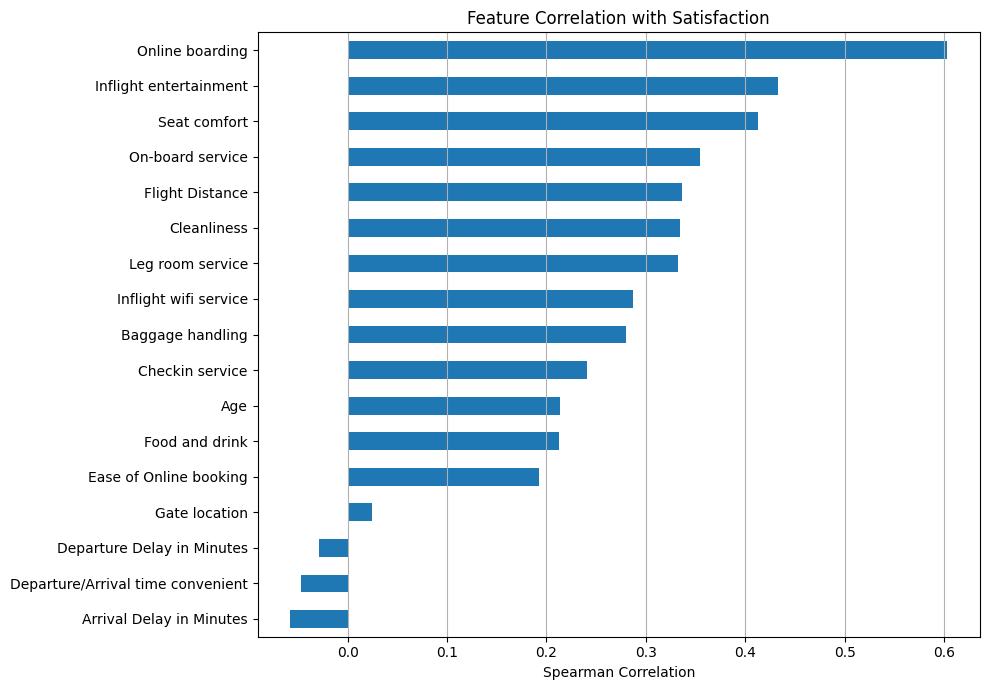

In [17]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

y_train_encoded = pd.Series(
    encoder.fit_transform(y_train),
    index=y_train.index
)

correlations = X_train[numerical_features].corrwith(
    y_train_encoded,
    method="spearman"
)

correlations = correlations.sort_values()

correlations.plot(
    kind="barh",
    figsize=(10, 7)
)

plt.title("Feature Correlation with Satisfaction")
plt.xlabel("Spearman Correlation")
plt.grid(axis="x")
plt.tight_layout()
plt.show()

## Building a model using Logistic Regression

In [58]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold

cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

full_pipeline = Pipeline([
    ("preprocessing", preprocessing),
    ("log_reg", LogisticRegression(solver='lbfgs', max_iter=1000, random_state=42))
])

param_grid = {'log_reg__C': [0.0001, 0.001, 0.01, 0.1, 1.0, 10.0, 100]}


grid_search =  GridSearchCV(full_pipeline, param_grid, cv=cv_strategy,
                            scoring='roc_auc',
                            n_jobs=-1)

grid_search.fit(X_train, y_train)


GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('preprocessing',
                                        ColumnTransformer(transformers=[('pipeline-1',
                                                                         Pipeline(steps=[('simpleimputer',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('standardscaler',
                                                                                          StandardScaler())]),
                                                                         <sklearn.compose._column_transformer.make_column_selector object at 0x7ed7f4d7c7d0>),
                                                                        (...
                                                                         Pipeline(steps=[('simpleimputer',
                                                                                          SimpleImputer(strategy='most_frequent')),
                                                                                         ('onehotencoder',
                                                                                          OneHotEncoder(handle_unknown='ignore'))]),
                                                                         <sklearn.compose._column_transformer.make_column_selector object at 0x7ed8111ba2c0>)])),
                                       ('log_reg',
                                        LogisticRegression(max_iter=1000,
                                                           random_state=42))]),
             n_jobs=-1,
             param_grid={'log_reg__C': [0.0001, 0.001, 0.01, 0.1, 1.0, 10.0,
                                        100]},
             scoring='roc_auc')

## Model Evaluation

In [59]:
from sklearn.metrics import roc_auc_score

best_model = grid_search.best_estimator_

y_proba = best_model.predict_proba(X_valid)[:,1]

print("Validation ROC-AUC:", roc_auc_score(y_valid, y_proba))

Validation ROC-AUC: 0.920456996794182


In [60]:
print("Best parameters:", grid_search.best_params_)
print("Best CV ROC-AUC:", grid_search.best_score_)

Best parameters: {'log_reg__C': 0.01}
Best CV ROC-AUC: 0.9218622527021356


This is such a pretty strong baseline model. I was actually planning to run a `Random Forest Classifier`. But it's computationally expensive and takes a lot of time to train. So I will just keep `Logistic Regression` as the final model.

## Keeping logistic regression as the final model


In [61]:
test_data = pd.read_csv("/content/Datasets/test.csv")
test_ids = test_data["id"]

X_test = test_data.drop("id", axis=1)

In [62]:
from sklearn.base import clone

best_log_reg = clone(grid_search.best_estimator_)

best_log_reg.fit(X, y)

test_proba = best_log_reg.predict_proba(X_test)[:, 1]

# Creating a submission file for kaggle competition

In [63]:
submission = pd.DataFrame({
    "id": test_ids,
    "satisfaction": test_proba
})

submission.to_csv('submission.csv', index=False)

In [64]:
print(submission.head())
print(submission.shape)
print(submission.isnull().sum())

       id  satisfaction
0  699635      0.090643
1  699636      0.580451
2  699637      0.469899
3  699638      0.139628
4  699639      0.003387
(299844, 2)
id              0
satisfaction    0
dtype: int64


In [65]:
from google.colab import files

files.download("submission.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>